# Практическое занятие №2: Градиентный спуск и оптимизаторы
**Цели занятия:**
- Научиться визуализировать функции потерь двух переменных (3D и линии уровня).
- Реализовать простой градиентный спуск (SGD) с помощью PyTorch и проследить траекторию оптимизации.
- Познакомиться с основными оптимизаторами из семейства gradient descent: SGD с моментом, RMSprop, Adam.
- Исследовать влияние скорости обучения (learning rate) на сходимость.

Слова "**Задание**" выделены жирным шрифтом по тексту.

## 1. Импорт необходимых библиотек
Установка и импорт:
- `torch` для автоматического дифференцирования и оптимизаторов.
- `numpy` для численных операций.
- `matplotlib` для построения графиков (3D, контурные, анимация).
- `ipywidgets` (опционально) для интерактивности.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from IPython.display import HTML
import warnings
import plotly.graph_objects as go
warnings.filterwarnings('ignore')

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 2. Функции для визуализации
Определим две классические тестовые функции:
- **Функция Розенброка** (Rosenbrock) — «овражная» функция, сложная для оптимизации:
  $$f(x,y) = (a - x)^2 + b\,(y - x^2)^2,\quad a=1,\; b=100.$$
  Глобальный минимум в точке $(1,1)$.
- **Функция Химмельблау** (Himmelblau) — с несколькими локальными минимумами:
  $$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
  Четыре локальных минимума: $(3,2)$, $(-2.805,3.131)$, $(-3.779,-3.283)$, $(3.584,-1.848)$.

In [75]:
def rosenbrock(x, y, a=1, b=100):
    return (a - x)**2 + b * (y - x**2)**2

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

# Создадим сетку для построения графиков
x = np.linspace(-2, 2, 100)
y = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x, y)
Z_rosen = rosenbrock(X, Y)

# Для Химмельблау возьмём более широкий диапазон
x_h = np.linspace(-5, 5, 100)
y_h = np.linspace(-5, 5, 100)
X_h, Y_h = np.meshgrid(x_h, y_h)
Z_himm = himmelblau(X_h, Y_h)

### 2.1 3D-визуализация функций
**Задание 1**: построить поверхности функций Розенброка и Химмельблау в 3D с возможностью интерактивного вращения. Обратите внимание на овраг у Розенброка и несколько впадин у Химмельблау.

Пример можно взять из лекции (библиотека plotly).

In [3]:
# Строим поверхность функции Розенброка
fig = go.Figure()

fig.add_trace(go.Surface(
    x=x,
    y=y,
    z=Z_rosen,
    colorscale='Viridis',
    opacity=0.9,
    name='Z_rosen',
    colorbar=dict(title='f(x, y)')
))

# Глобальный минимум
fig.add_trace(go.Scatter3d(
    x=[1.0],
    y=[1.0],
    z=[rosenbrock(1.0, 1.0)],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=['Глобальный минимум'],
    textposition='top center',
    textfont=dict(color='red', size=12),
    name='Глобальный'
))

# Настройка макета
fig.update_layout(
    title='3D‑функция с глобальным минимумом',
    scene=dict(
        xaxis_title='x',
        yaxis_title='y',
        zaxis_title='Z_rosen',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.5))
    ),
    width=800,
    height=600
)

# Показать график (откроется в браузере)
fig.show()

# Сохранить в HTML (можно открыть без Python)
# fig.write_html('two_minima_3d.html')

In [4]:
# Строим поверхность Химмельблау
fig = go.Figure()

fig.add_trace(go.Surface(
    x=x_h,
    y=x_h,
    z=Z_himm,
    colorscale='Viridis',
    opacity=0.9,
    name='Z_himm',
    colorbar=dict(title='f(x, y)')
))

# Глобальные минимумы
fig.add_trace(go.Scatter3d(
    x=[3.0],
    y=[2.0],
    z=[himmelblau(3.0, 2.0)],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=['Локальный минимум'],
    textposition='top center',
    textfont=dict(color='red', size=12),
    name='Локальный'
))


fig.add_trace(go.Scatter3d(
    x=[-2.805],
    y=[3.131],
    z=[himmelblau(-2.805, 3.131)],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=['Локальный минимум'],
    textposition='top center',
    textfont=dict(color='red', size=12),
    name='Локальный'
))

fig.add_trace(go.Scatter3d(
    x=[-3.779],
    y=[-3.283],
    z=[himmelblau(-3.779, -3.283)],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=['Локальный минимум'],
    textposition='top center',
    textfont=dict(color='red', size=12),
    name='Локальный'
))

fig.add_trace(go.Scatter3d(
    x=[3.584],
    y=[-1.848],
    z=[himmelblau(3.584, -1.848)],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=['Локальный минимум'],
    textposition='top center',
    textfont=dict(color='red', size=12),
    name='Локальный'
))



# Настройка макета
fig.update_layout(
    title='3D‑функция с глобальными минимумами',
    scene=dict(
        xaxis_title='x',
        yaxis_title='y',
        zaxis_title='Z_himm',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.5))
    ),
    width=800,
    height=600
)

# Показать график (откроется в браузере)
fig.show()

# Сохранить в HTML (можно открыть без Python)
# fig.write_html('two_minima_3d.html')

### 2.2 Контурные графики (линии уровня)
**Задание 2.** Нарисовать контурные графики и точки глобальных (или локальных) минимумов на них.
Можно использовать matplotlib или seaborn. (Проявить фантазию в оформлении!)

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.optim import SGD, Adam, RMSprop

# Универсальная функция для запуска оптимизаторов
def run_optimizers(loss_fn, x0, steps, lr):
    optimizers = {
        'SGD': lambda params: SGD(params, lr=lr),
        'Momentum': lambda params: SGD(params, lr=lr, momentum=0.9),
        'RMSprop': lambda params: RMSprop(params, lr=lr),
        'Adam': lambda params: Adam(params, lr=lr)
    }

    def optimize(opt_name, opt_creator):
        # clone() - создание копии начальной точки, чтобы не изменять оригинал
        # detach() - отсоединение от вычислительного графа (без хранения истории)
        x = x0.clone().detach().requires_grad_(True)
        path = [x.detach().numpy().copy()]
        optimizer = opt_creator([x])
        for _ in range(steps):
            optimizer.zero_grad()
            loss = loss_fn(x[0], x[1])
            loss.backward()
            optimizer.step()
            path.append(x.detach().numpy().copy())
        return np.array(path)

    paths = {name: optimize(name, creator) for name, creator in optimizers.items()}
    return paths

# Вспомогательная функция для построения контурного графика с траекториями
def plot_contour_with_paths_rozen(X, Y, Z, paths, title, xlabel='x', ylabel='y'):
    plt.figure(figsize=(12, 10))
    plt.contour(X, Y, Z, levels=20, cmap='jet') # levels - кол-во линий функции потерь; cmap - цветовой переход
    colors = {'SGD': 'red', 'Momentum': 'blue', 'RMSprop': 'green', 'Adam': 'orange'}

    for name, path in paths.items():
        plt.plot(path[:, 0], path[:, 1], color=colors[name], label=name, alpha=0.7)
        plt.plot(path[0, 0], path[0, 1], 'o', color=colors[name], markersize=5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.plot(1.0, 1.0, 'r*', markersize=15, label='Истина')
    plt.legend()
    plt.colorbar(label='loss')
    plt.show()

# Вспомогательная функция для построения контурного графика с траекториями
def plot_contour_with_paths_himm(X, Y, Z, paths, title, xlabel='x', ylabel='y'):
    plt.figure(figsize=(12, 10))
    plt.contour(X, Y, Z, levels=20, cmap='jet') # levels - кол-во линий функции потерь; cmap - цветовой переход
    colors = {'SGD': 'red', 'Momentum': 'blue', 'RMSprop': 'green', 'Adam': 'orange'}

    for name, path in paths.items():
        plt.plot(path[:, 0], path[:, 1], color=colors[name], label=name, alpha=0.7)
        plt.plot(path[0, 0], path[0, 1], 'o', color=colors[name], markersize=5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.plot(3.0, 2.0, 'r*', markersize=15, label='Истина')
    plt.plot(-2.805, 3.131, 'r*', markersize=15, label='Истина')
    plt.plot(-3.779, -3.283, 'r*', markersize=15, label='Истина')
    plt.plot(3.584, -1.848, 'r*', markersize=15, label='Истина')
    plt.legend()
    plt.colorbar(label='loss')
    plt.show()


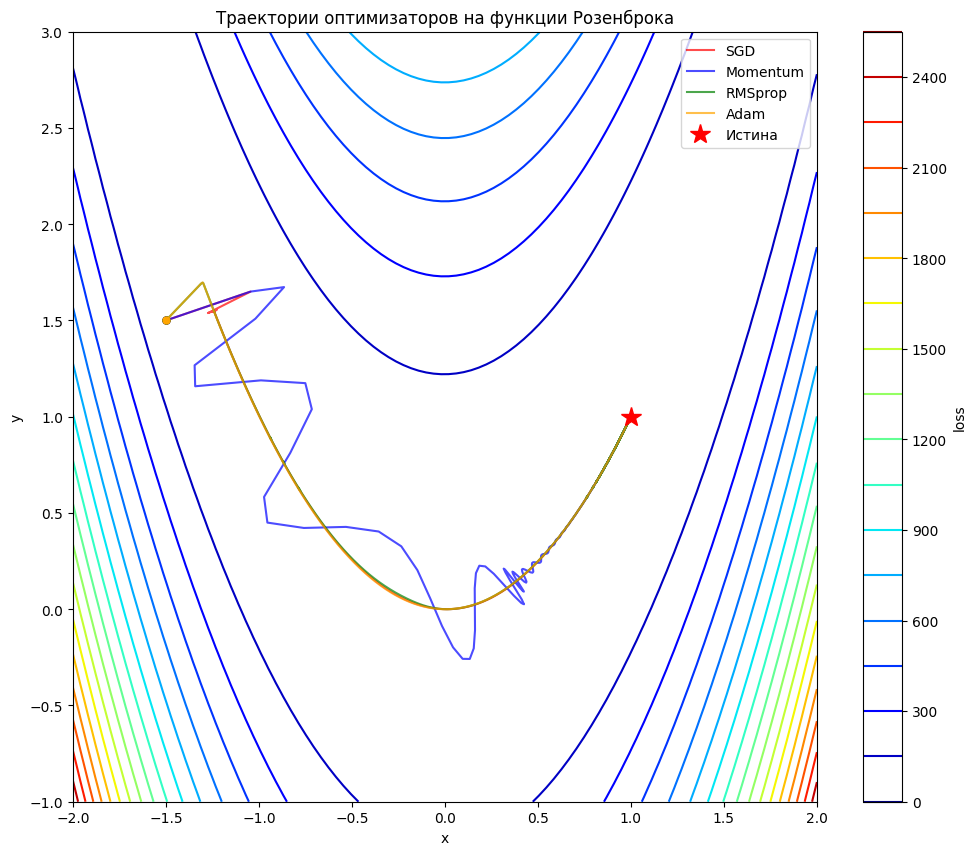

Конечные значения для различных методов: 
SGD: [0.9968366 0.9936705]
Momentum: [0.9999995 0.999999 ]
RMSprop: [1.0003405  0.99918103]
Adam: [0.9939241  0.98786753]


In [6]:
x0 = torch.tensor([-1.5, 1.5], dtype=torch.float32)
paths_rosen = run_optimizers(rosenbrock, x0, 12500, 0.001)
plot_contour_with_paths_rozen(X, Y, Z_rosen, paths_rosen, 'Траектории оптимизаторов на функции Розенброка')

print('Конечные значения для различных методов: ')
for name in paths_rosen:
  print(f"{name}: {paths_rosen[name][-1]}")

Потребовалось 12500 шагов для достаточного обучения всех методов, но некоторые из них быстрее достигли глобального минимума.

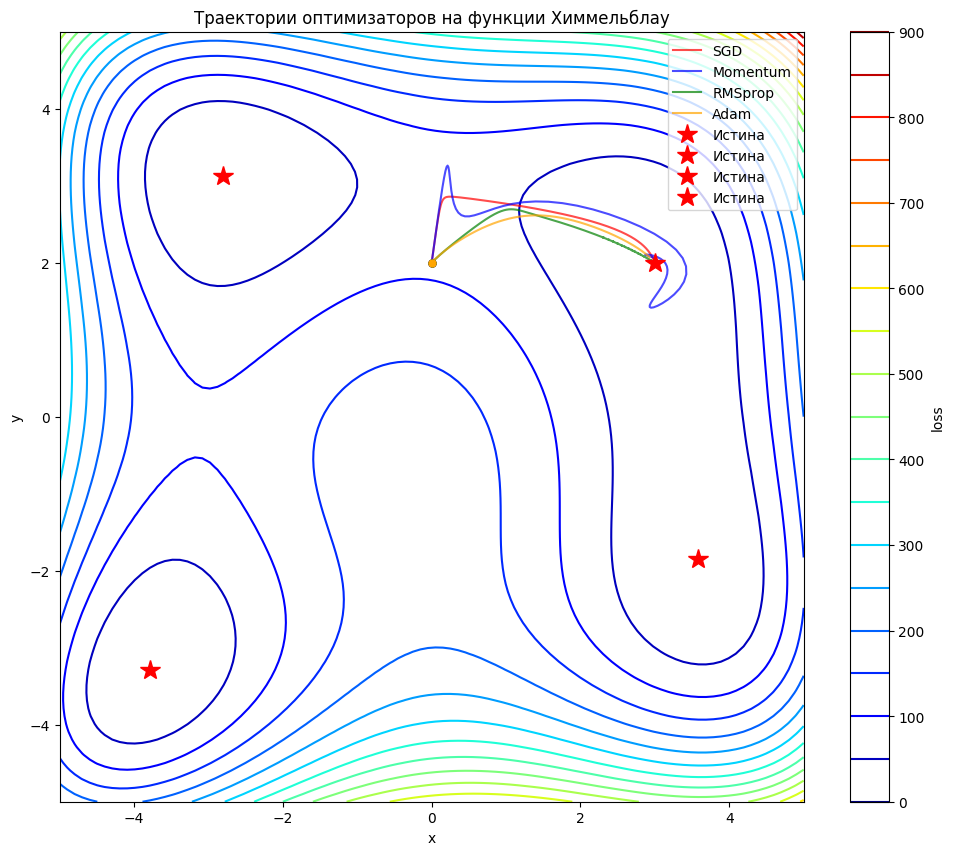

Конечные значения для различных методов: 
SGD: [2.9999971 2.000005 ]
Momentum: [3. 2.]
RMSprop: [2.9883342 2.0064151]
Adam: [2.9290044 2.0722141]


In [7]:
x0 = torch.tensor([0, 2], dtype=torch.float32)
paths_himm = run_optimizers(himmelblau, x0, 3000, 0.001)
plot_contour_with_paths_himm(X_h, Y_h, Z_himm, paths_himm, 'Траектории оптимизаторов на функции Химмельблау')

print('Конечные значения для различных методов: ')
for name in paths_himm:
  print(f"{name}: {paths_himm[name][-1]}")

Потребовалось 3000 шагов для достаточного обучения всех методов, но некоторые из них быстрее достигли глобального минимума. При разных начальных точках все методы устремлялись к ближайшим локальным минимумам.

**Задание 3.** Изучите полученные графики. Почему функция Розенброка считается сложной для градиентного спуска? (Ответьте в ячейке ниже)

Функция Розенброка сложна для градиентного спуска, т.к. в ней присутствует затухающий градиент (т.е. частные прозводные уже принимают значения, близкие к 0, хотя глобальный минимум еще не дсотигнут), который еще тянется по кривой линии. Чтобы все методы почти достигли глобального минимума в точке (1, 1), пришлось указать 12500 шагов (конечно, некоторые методы справились быстрее, чем за такое кол-во итераций) при скорости обучения 0.001

## 3. Реализация градиентного спуска (SGD) с помощью PyTorch

Будем минимизировать функцию двух переменных, используя автоматическое дифференцирование PyTorch. Создадим тензоры с включённым `requires_grad=True` и на каждом шаге будем обновлять их с помощью правила SGD:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t).$$

В цикле оптимизации необходимо:
1. Вычислить значение функции.
2. Вызвать `.backward()` для вычисления градиентов.
3. Обновить параметры вручную (или с помощью оптимизатора).
4. Обнулить градиенты (`.grad.zero_()`).

Напишем функцию, которая выполняет заданное количество шагов SGD и записывает траекторию.

In [8]:
def sgd_trajectory(func, x0, y0, lr=0.01, steps=50):
    """
    Выполняет SGD для функции func(x,y) от двух переменных.
    Возвращает списки x_hist, y_hist, f_hist.
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        # Вычисляем функцию
        f = func(x, y)
        # Сохраняем историю (отсоединяем от графа вычислений)
        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

        # Градиенты
        f.backward()

        # Обновление вручную (SGD)
        with torch.no_grad():
            x -= lr * x.grad
            y -= lr * y.grad

        # Обнуляем градиенты
        x.grad.zero_()
        y.grad.zero_()

    return x_hist, y_hist, f_hist

Протестируем на функции Розенброка с начальной точкой (-1.5, 1.5), learning rate = 0.001 и 200 шагов. Построим траекторию на контурном графике.

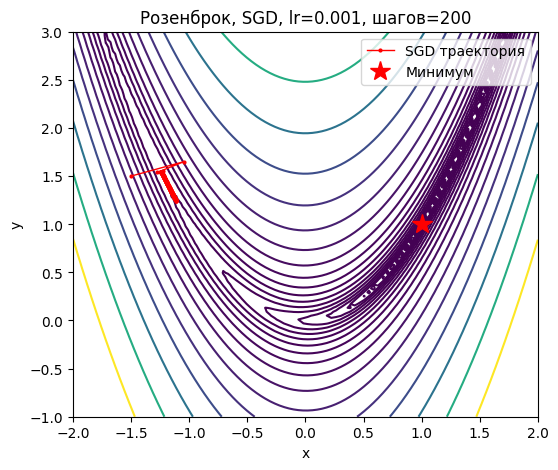

In [9]:
x0, y0 = -1.5, 1.5
lr = 0.001
steps = 200

x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, x0, y0, lr, steps)

# Визуализация
plt.figure(figsize=(6,5))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis')
plt.plot(x_hist, y_hist, 'r.-', markersize=4, linewidth=1, label='SGD траектория')
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Розенброк, SGD, lr={lr}, шагов={steps}')
plt.legend()
plt.show()

**Задание 4.** Поэкспериментируйте с learning rate и начальной точкой. Попробуйте для обеих функций:
- Попробовать 5 различных значений learning rate (например, 0.01, 0.05). Что происходит?
- Попробовать 5 различных начальных точек, например (0, 2) или (-1, -1) или случаным образом выбранных, надётся ли действительный глобальный минимум?

Результирующие графики всех экспериментов сохраните в отчётном блокноте.



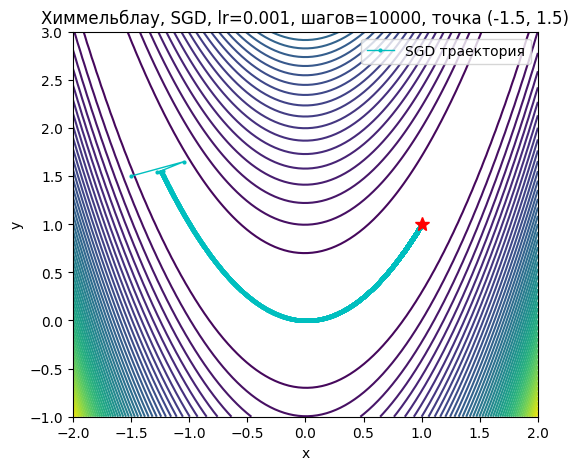

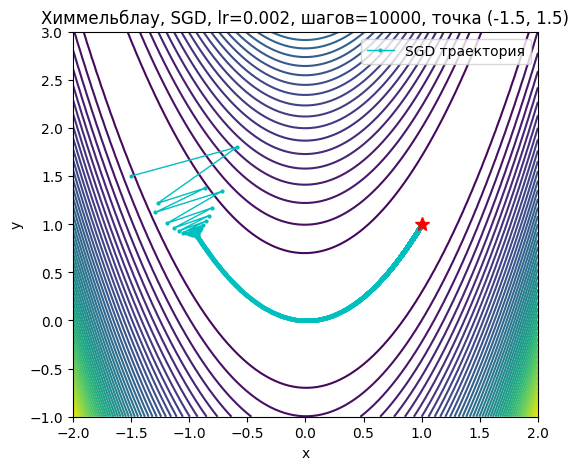

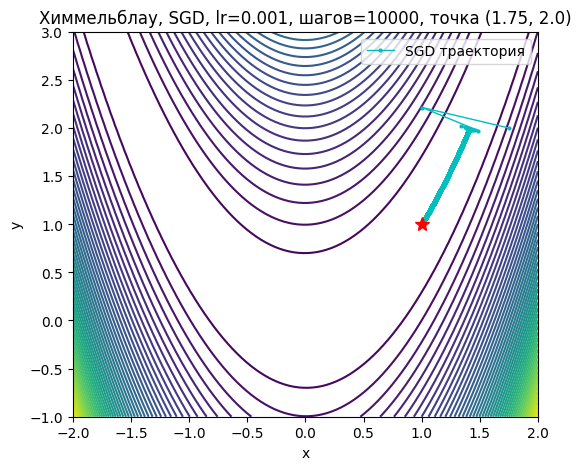

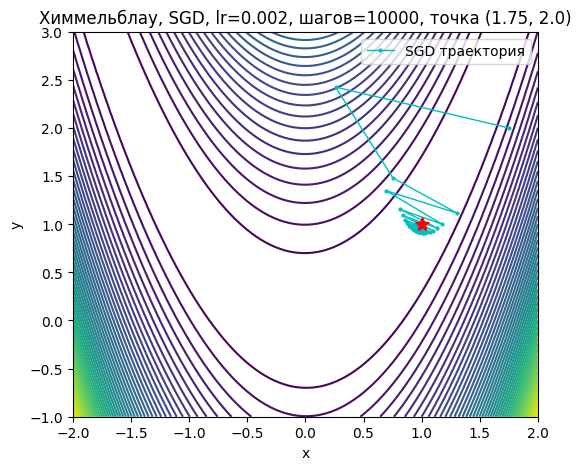

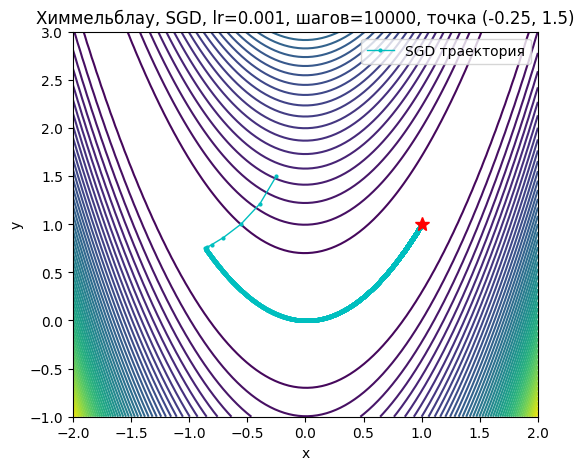

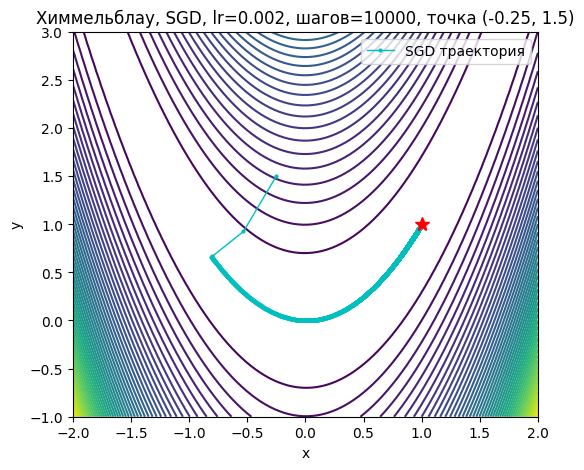

In [10]:
# Эксперимент с функцией Розенброка
points_list = [(-1.5, 1.5), (1.75, 2.0), (-0.25, 1.5)]
lr_list = [0.001, 0.002]
minima = [(1.0, 1.0)]
steps = 10000


for point in points_list:
  x0, y0 = point
  for lr in lr_list:
    x_hist, y_hist, f_hist_h = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.figure(figsize=(6,5))
    plt.contour(X, Y, Z_rosen, levels=50, cmap='viridis')
    plt.plot(x_hist, y_hist, 'c.-', markersize=4, linewidth=1, label='SGD траектория')
    for mx, my in minima:
      plt.plot(mx, my, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Химмельблау, SGD, lr={lr}, шагов={steps}, точка ({x0}, {y0})')
    plt.legend()
    plt.show()

По графикам видно, что с большей скоростью обучения возрастают шаги, с которыми считаются промежуточные точки до глобального минимума. Также можно заметить, что при большей скорости обучения (0.002) происходит скачок через овраг, который представлен в виде кривой с затухающим градиентом. А при меньшей скорости обучения (0.001) данного скачка не происходит, промежуточные точки уже находятся на кривой с затухающим градиентом, как только ее достигают. При всех начальных условиях был достигнут глобальный минимум.

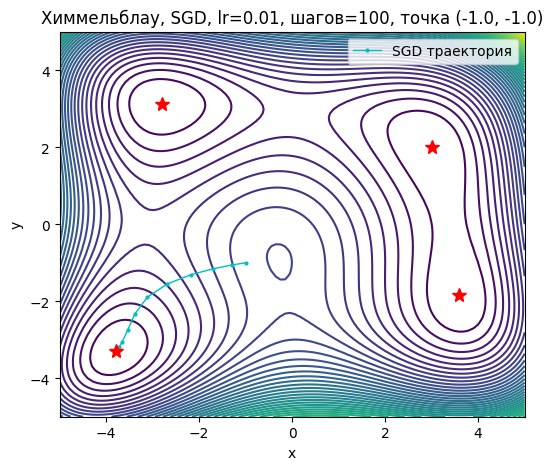

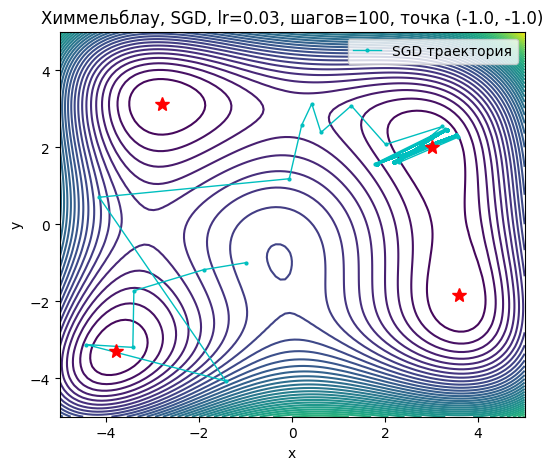

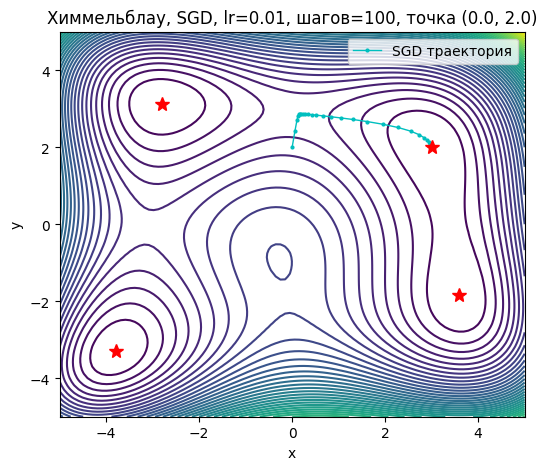

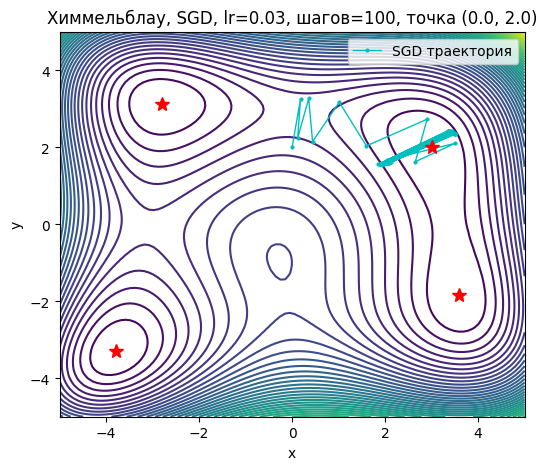

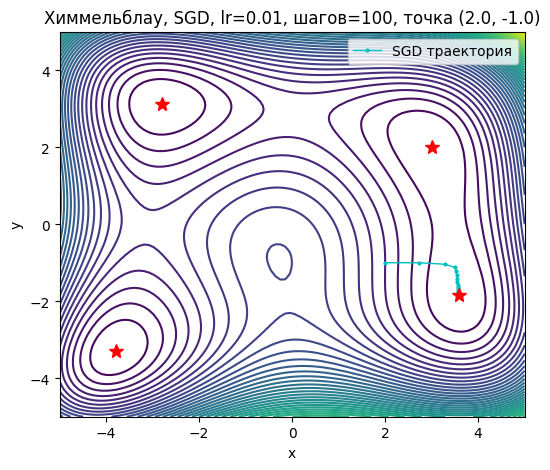

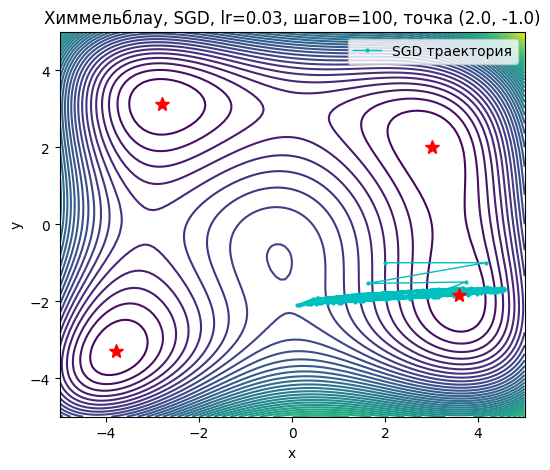

In [11]:
# Эксперимент с функцией Химмельблау
points_h_list = [(-1.0, -1.0), (0.0, 2.0), (2.0, -1.0)]
lr_h_list = [0.01, 0.03]
minima = [(3.0, 2.0), (-2.805, 3.131), (-3.779, -3.283), (3.584, -1.848)]
steps_h = 100


for point in points_h_list:
  x0_h, y0_h = point
  for lr_h in lr_h_list:
    x_hist_h, y_hist_h, f_hist_h = sgd_trajectory(himmelblau, x0_h, y0_h, lr_h, steps_h)
    plt.figure(figsize=(6,5))
    plt.contour(X_h, Y_h, Z_himm, levels=50, cmap='viridis')
    plt.plot(x_hist_h, y_hist_h, 'c.-', markersize=4, linewidth=1, label='SGD траектория')
    for mx, my in minima:
      plt.plot(mx, my, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Химмельблау, SGD, lr={lr_h}, шагов={steps_h}, точка ({x0_h}, {y0_h})')
    plt.legend()
    plt.show()

По графикам видно, что с большей скоростью обучения возрастают шаги, с которыми считаются промежуточные точки до локального минимума. Также можно заметить, что при большей скорости обучения (0.03) происходят скачки через точки, где частная производная максимально близка к 0. А при меньшей скорости обучения (0.01) таких скачков не происходит. При всех начальных условиях были достигнуты локальные минимумы, хотя в некоторых случаях один локальный минимум был перепрыгнут, после чего происходило попадание в другой локальный минимум (скорость обучения 0.03, точка старта (-1, -1)).

## 4. Сравнение оптимизаторов из torch.optim

PyTorch предоставляет готовые реализации многих оптимизаторов: SGD (с momentum и nesterov), RMSprop, Adam и др. Мы можем использовать их, передав параметры модели. В нашем случае модель — это просто два тензора x и y.

Напишем функцию, которая принимает оптимизатор (например, `torch.optim.SGD`), его параметры и возвращает траекторию.

In [17]:
def optimizer_trajectory(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

### 4.1 Сравнение на функции Розенброка
Возьмём начальную точку (-1.5, 1.5), 100 шагов, и сравним:
- SGD (learning rate = 0.001)
- SGD с моментом (lr=0.001, momentum=0.9)
- RMSprop (lr=0.01)
- Adam (lr=0.01)

Построим все траектории на одном контурном графике.

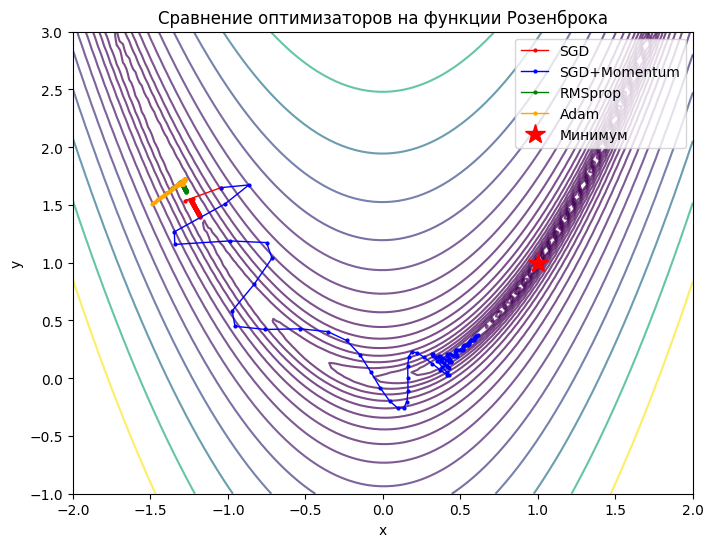

In [70]:
x0, y0 = -1.5, 1.5
steps = 100

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

**Задание 5. Вопросы для анализа:**
- Какой оптимизатор быстрее достиг окрестности минимума?
- Как ведёт себя SGD без момента? Почему он "застревает" в овраге?
- Почему Adam и RMSprop работают лучше?
- Сравнить оптимизаторы по итоговому найденному значению минимизируемой функции.
- Сравнить времена работы (эффективность/производительность) оптимизаторов. Если на одинаковом количестве итераций они оказались примерно одинаковые, попробовать увеличить количество итераций так, чтобы 1-2 метода успели попасть в небольшую окрестность глобального минимума и сравнить методы по количеству этих итераций.


1) Быстрее всего минимума достиг оптимизатор SGD+Momentum.
2) SGD без момента застревает в овраге, т.к. у него нету инерционной составляющей, один его шаг на пути к глобальному минимуму меньше, чем у SGD+Momentum.
3) Adam и RMSprop работают лучше, т.к. у них адаптивная скорость обучения из-за учета скользящего среднего квадратов градиентов. Если градиент большой — скорость обучения уменьшается. Если градиент маленький — скорость увеличивается.
4) За 100 шагов лучше всех приблизился к глобальному минимуму оптимизатор SGD+Momentum, остальные смогли только достичь кривой с затухающим градиентом и немного по ней продвинуться.
5) SGD достиг глобального минимума за 7000 шагов со скоростью обучения 0.001. SGD+Momentum достиг глобального минимума за 1000 шагов со скоростью обучения 0.001 и momentum = 0.9. RMSprop достиг глобального минимума за 3000 шагов со скоростью обучения 0.01. Adam достиг глобального минимума за 5000 шагов со скоростью обучения 0.01. Градация методов по эффективности (от наиболее к наименее эффективному): SGD+Momentum (1,5 секунды), RMSprop (2,5 секунды), Adam (3,5 секунды), SGD (3,5 секунды).

### 4.2 Анимация траекторий (дополнительно)
Для наглядности можно создать анимацию движения точек. Ниже приведён код для создания GIF-анимации с помощью matplotlib.animation. Запустите эту ячейку, чтобы увидеть, как оптимизаторы "шагают" к минимуму.

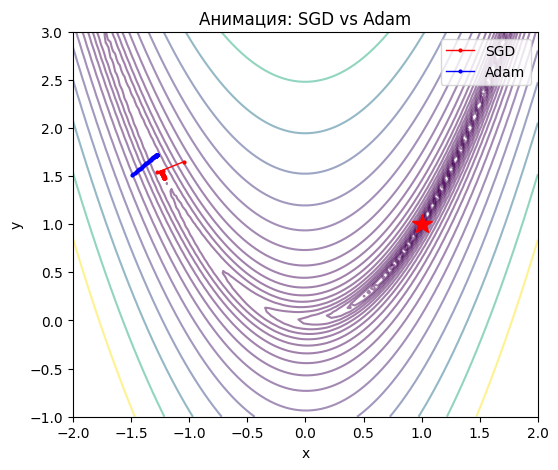

In [71]:
# Создаём анимацию для двух оптимизаторов: SGD и Adam
fig, ax = plt.subplots(figsize=(6,5))
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax.plot(1, 1, 'r*', markersize=15)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Анимация: SGD vs Adam')

line_sgd, = ax.plot([], [], 'r.-', lw=1, markersize=4, label='SGD')
line_adam, = ax.plot([], [], 'b.-', lw=1, markersize=4, label='Adam')
ax.legend()

# Получаем траектории (первые steps точек)
steps_anim = 50  # возьмём первые 50 шагов для анимации
x_sgd, y_sgd = trajectories['SGD'][0][:steps_anim], trajectories['SGD'][1][:steps_anim]
x_adam, y_adam = trajectories['Adam'][0][:steps_anim], trajectories['Adam'][1][:steps_anim]

def init():
    line_sgd.set_data([], [])
    line_adam.set_data([], [])
    return line_sgd, line_adam

def animate(i):
    line_sgd.set_data(x_sgd[:i+1], y_sgd[:i+1])
    line_adam.set_data(x_adam[:i+1], y_adam[:i+1])
    return line_sgd, line_adam

anim = animation.FuncAnimation(fig, animate, init_func=init, frames=steps_anim, interval=100, blit=True)

# Для отображения в блокноте:
HTML(anim.to_html5_video())
# Если не работает, можно сохранить в gif: anim.save('comparison.gif', writer='pillow')

## 5. Влияние скорости обучения (learning rate) на сходимость

Проведём эксперимент: зафиксируем начальную точку (-1.5, 1.5) и оптимизатор SGD (без момента). Будем менять learning rate: очень маленький (0.0001), средний (0.001), большой (0.01) и слишком большой (0.1). Наблюдаем поведение.

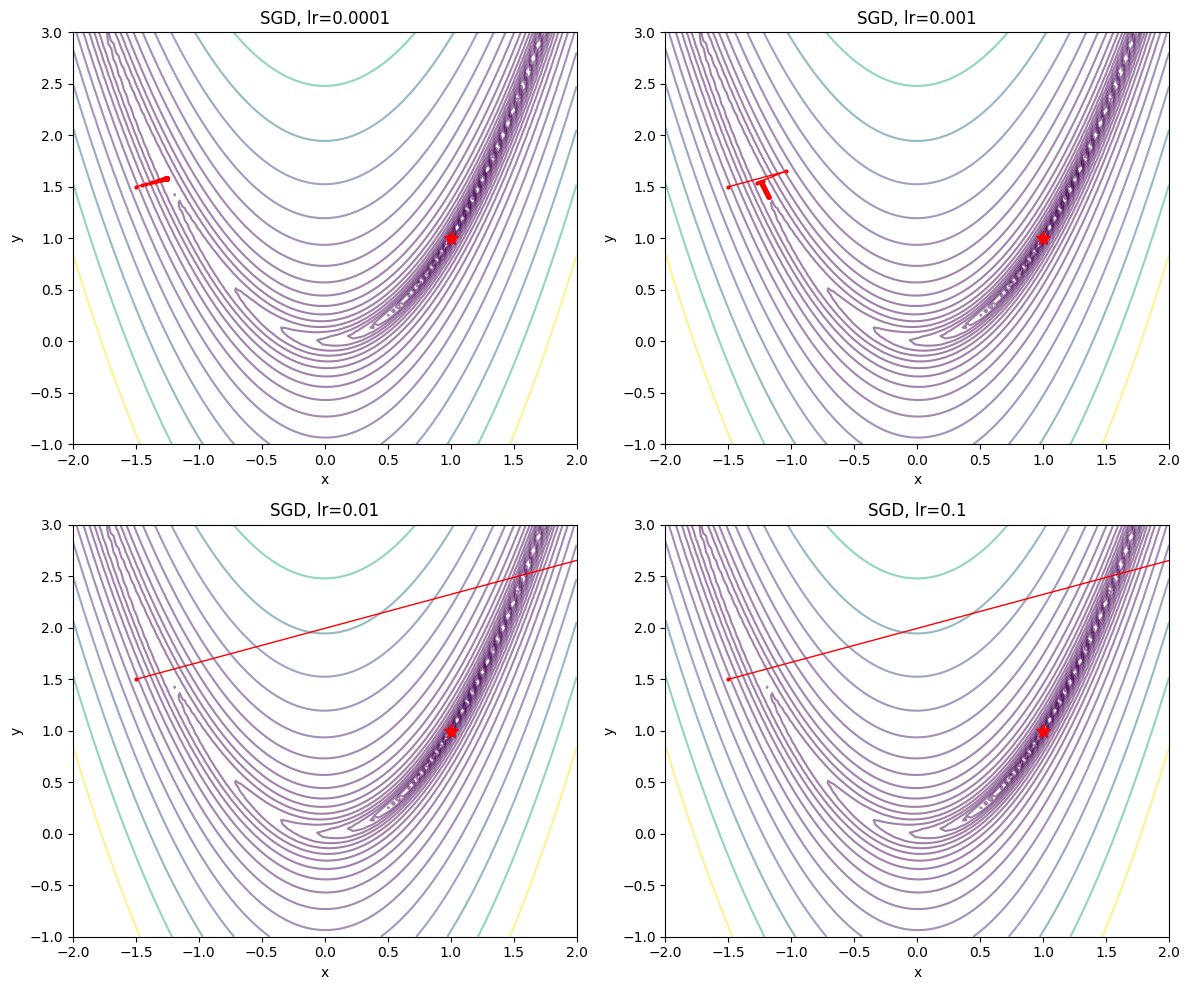

In [72]:
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = -1.5, 1.5
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    plt.plot(1, 1, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-2,2)
    plt.ylim(-1,3)

plt.tight_layout()
plt.show()

**Обсуждение:**
- При очень маленьком LR (0.0001) алгоритм не успевает дойти до минимума за 100 шагов.
- При LR=0.001 траектория медленно сползает в овраг и движется к минимуму.
- При LR=0.01 шаги больше, но из-за оврага траектория может "перепрыгивать" и колебаться.
- При LR=0.1 градиентный спуск расходится: шаги становятся настолько большими, что точка улетает за пределы графика. Это иллюстрация "взрыва градиентов" (хотя здесь не градиенты взрываются, а слишком большой шаг).

**Задание 6.** Для функции Химмельблау и начальной точки (0, 0) подберите такое значение learning rate для SGD, чтобы алгоритм сошёлся к одному из минимумов, но при этом траектория была "интересной" (например, с колебаниями). Попробуйте также очень большое LR и посмотрите, куда улетает точка.

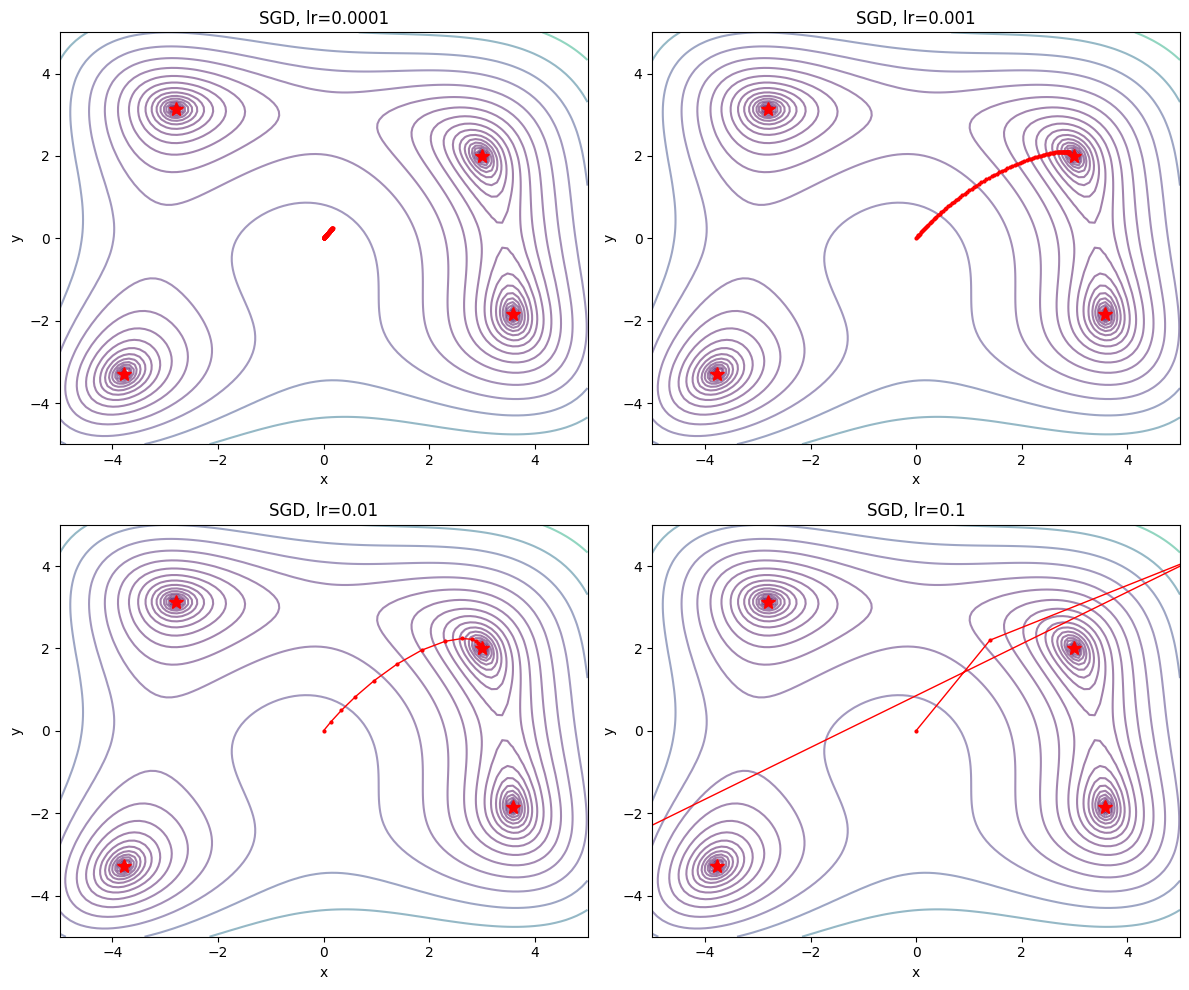

In [78]:
# Ваш эксперимент с Химмельблау и разными LR
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = 0.0, 0.0
minima = [(3.0, 2.0), (-2.805, 3.131), (-3.779, -3.283), (3.584, -1.848)]
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(himmelblau, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X_h, Y_h, Z_himm, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    for mx, my in minima:
      plt.plot(mx, my, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-5,5)
    plt.ylim(-5,5)

plt.tight_layout()
plt.show()



Оптимизатор за 100 шагов и со скоростями обучения 0.001, 0.01 смог достигнуть одного из минимумов функции. Скорости 0.0001 не хватило, т.к. шаги слишком малы. Скорость 0.1 оказалась слишком большой, т.к. шаги ушли за пределы минимумов, перепрыгнули их.